In [62]:
from pathlib import Path
import pandas as pd

data_dir = Path(r"D:\college_coding\airline_ontime_analysis\data")

airport_dfs = {}

for airport_dir in data_dir.iterdir():
    if airport_dir.is_dir():
        csv_files = list(airport_dir.glob("*.csv"))
        if csv_files:
            try:
                airport_dfs[airport_dir.name] = pd.concat(
                    [pd.read_csv(file, low_memory=False) for file in csv_files],
                    ignore_index=True
                )
            except Exception as e:
                print(f"Error reading CSV files for {airport_dir.name}: {e}")

print(f"Loaded {len(airport_dfs)} airport dataframes")

Loaded 10 airport dataframes


In [63]:
for airport_key, df in airport_dfs.items():
    origin_code = airport_key[:3].upper()

    if "Origin Airport" in df.columns:
        df["Origin Airport"] = origin_code
        df.insert(df.columns.get_loc("Destination Airport"), "Origin Airport", df.pop("Origin Airport"))
    else:
        df.insert(df.columns.get_loc("Destination Airport"), "Origin Airport", origin_code)

In [64]:
airport_dfs["atl-atlanta"]

,Carrier Code,Date (MM/DD/YYYY),Flight Number,Tail Number,Origin Airport,Destination Airport,Scheduled departure time,Actual departure time,Scheduled elapsed time (Minutes),Actual elapsed time (Minutes),Departure delay (Minutes),Wheels-off time,Taxi-Out time (Minutes),Delay Carrier (Minutes),Delay Weather (Minutes),Delay National Aviation System (Minutes),Delay Security (Minutes),Delay Late Aircraft Arrival (Minutes)
0,AS,01/01/2024,321,N972AK,ATL,SEA,18:02,18:12,343,309,10,18:27,15,0,0,0,0,0
1,AS,01/01/2024,377,N531AS,ATL,SEA,07:00,07:44,341,312,44,07:58,14,15,0,0,0,0
2,AS,01/01/2024,497,N590AS,ATL,SEA,09:00,09:01,343,325,1,09:23,22,0,0,0,0,0
3,AS,01/01/2025,321,N428AS,ATL,SEA,18:39,18:36,343,344,-3,18:53,17,0,0,0,0,0
4,AS,01/01/2025,355,N588AS,ATL,SAN,17:19,17:16,284,297,-3,17:35,19,0,0,0,0,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
584260,UA,12/31/2025,632,N18243,ATL,IAD,09:40,09:41,110,107,1,09:58,17,0,0,0,0,0
584261,UA,12/31/2025,1057,N77598,ATL,IAH,07:10,07:09,151,121,-1,07:24,15,0,0,0,0,0
584262,UA,12/31/2025,1259,N76288,ATL,SFO,08:25,08:22,335,367,-3,09:31,69,0,0,29,0,0
584263,UA,12/31/2025,1831,N13716,ATL,IAD,14:40,14:37,110,105,-3,14:53,16,0,0,0,0,0


In [65]:
import json

# Find airports.json in the data folder or its parent.
json_path = next(
    (path for path in [data_dir / "airports.json", data_dir.parent / "airports.json"]
     if path.exists()),
    None
)
if json_path is None:
    raise FileNotFoundError("Could not find airports.json")

with json_path.open(encoding="utf-8") as f:
    airports_data = json.load(f)

# Support JSON files containing either a code-keyed dictionary or a list of records.
airport_lookup = {}

def collect_airports(obj):
    if isinstance(obj, dict):
        code = next(
            (obj[key] for key in ("iata", "iata_code", "code", "airport_code")
             if key in obj and isinstance(obj[key], str)),
            None
        )
        if code:
            name = next(
                (obj[key] for key in ("name", "airport_name", "city") if key in obj),
                code
            )
            airport_lookup[code.upper()] = name

        for key, value in obj.items():
            if isinstance(key, str) and len(key) == 3 and isinstance(value, (str, dict)):
                airport_lookup.setdefault(key.upper(), value)
            collect_airports(value)
    elif isinstance(obj, list):
        for item in obj:
            collect_airports(item)

collect_airports(airports_data)

total_rows = sum(len(df) for df in airport_dfs.values())
print(f"Total rows across all airports: {total_rows:,}\n")
for airport_name, airport_df in airport_dfs.items():
    code = airport_name[:3].upper()
    print(f"{code} — {airport_lookup.get(code, 'Unknown airport')}: {len(airport_df):,} rows")


Total rows across all airports: 3,243,241

ATL — Hartsfield International, Atlanta, GA: 584,265 rows
DEN — Denver International, Denver, CO: 490,263 rows
DFW — Dallas/Ft.Worth International, Dallas/Ft. Worth, TX: 396,663 rows
JFK — John F Kennedy International, New York, NY: 173,249 rows
LAS — McCarran International, Las Vegas, NV: 305,281 rows
LAX — Los Angeles International, Los Angeles, CA: 280,867 rows
MCO — Orlando International, Orlando, FL: 276,556 rows
MIA — Miami International, Miami, FL: 181,688 rows
ORD — Chicago O'Hare International, Chicago, IL: 342,213 rows
SFO — San Francisco International, San Francisco, CA: 212,196 rows


In [66]:
all_airports_df = pd.concat(airport_dfs.values(), ignore_index=True)

def add_arrival_delay(df):
    df = df.copy()
    column = "Arrival delay (Minutes)"

    arrival_delay = (
        df["Actual elapsed time (Minutes)"]
        - df["Scheduled elapsed time (Minutes)"]
        + df["Departure delay (Minutes)"]
    )

    if column in df.columns:
        df = df.drop(columns=column)

    insert_at = df.columns.get_loc("Departure delay (Minutes)") + 1
    df.insert(insert_at, column, arrival_delay)
    return df

all_airports_df = add_arrival_delay(all_airports_df)
print(f"Combined rows: {len(all_airports_df):,}")
all_airports_df.head()

Combined rows: 3,243,241


,Carrier Code,Date (MM/DD/YYYY),Flight Number,Tail Number,Origin Airport,Destination Airport,Scheduled departure time,Actual departure time,Scheduled elapsed time (Minutes),Actual elapsed time (Minutes),Departure delay (Minutes),Arrival delay (Minutes),Wheels-off time,Taxi-Out time (Minutes),Delay Carrier (Minutes),Delay Weather (Minutes),Delay National Aviation System (Minutes),Delay Security (Minutes),Delay Late Aircraft Arrival (Minutes)
0,AS,01/01/2024,321,N972AK,ATL,SEA,18:02,18:12,343,309,10,-24,18:27,15,0,0,0,0,0
1,AS,01/01/2024,377,N531AS,ATL,SEA,07:00,07:44,341,312,44,15,07:58,14,15,0,0,0,0
2,AS,01/01/2024,497,N590AS,ATL,SEA,09:00,09:01,343,325,1,-17,09:23,22,0,0,0,0,0
3,AS,01/01/2025,321,N428AS,ATL,SEA,18:39,18:36,343,344,-3,-2,18:53,17,0,0,0,0,0
4,AS,01/01/2025,355,N588AS,ATL,SAN,17:19,17:16,284,297,-3,10,17:35,19,0,0,0,0,0


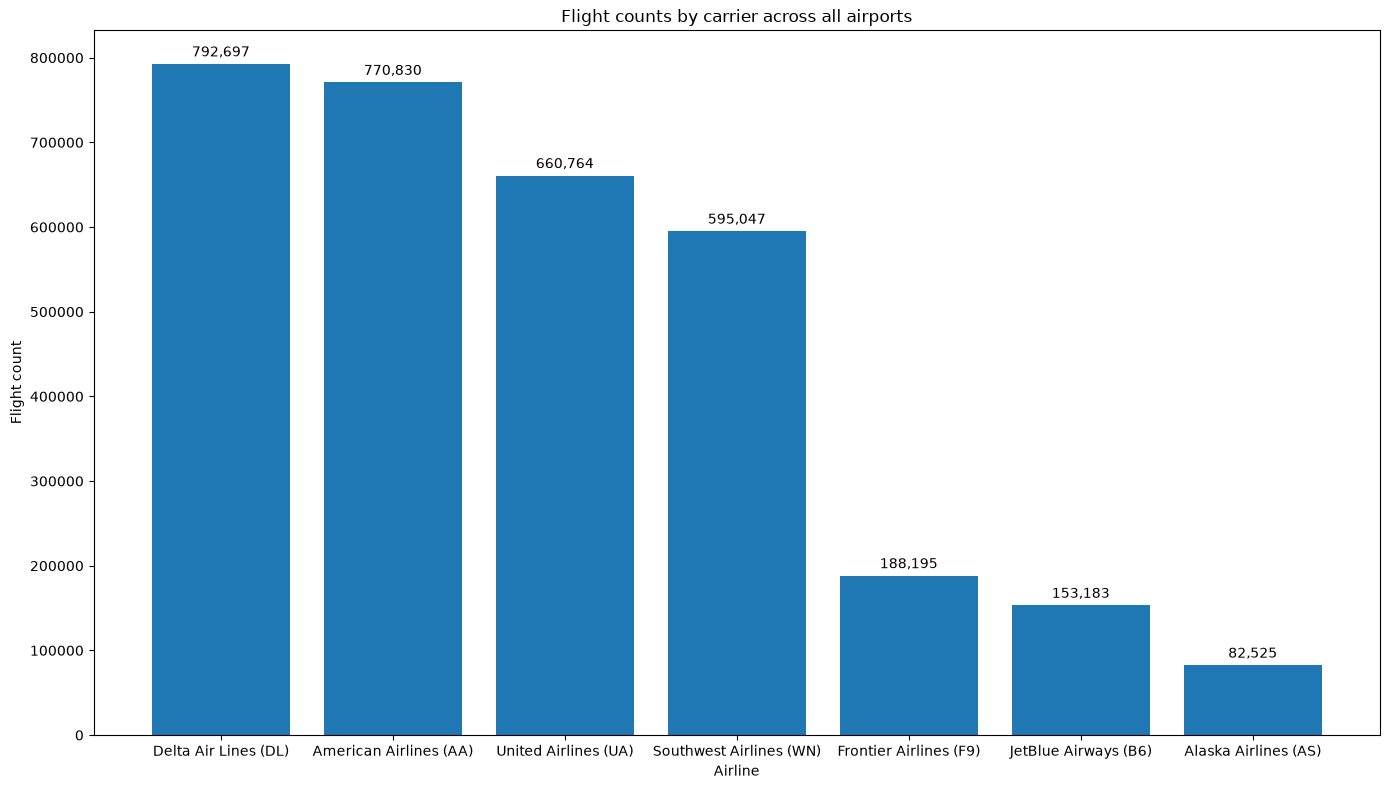

In [67]:
import json
import matplotlib.pyplot as plt

with open(data_dir / "carriers.json", encoding="utf-8") as file:
    carriers = json.load(file)

carrier_counts = all_airports_df["Carrier Code"].value_counts().sort_values(
    ascending=False
)
labels = [
    f"{carriers.get(code, code)} ({code})"
    for code in carrier_counts.index
]

fig, ax = plt.subplots(figsize=(14, 8))
bars = ax.bar(labels, carrier_counts.values)

ax.bar_label(bars, labels=[f"{count:,}" for count in carrier_counts.values], padding=3)
ax.set_xlabel("Airline")
ax.set_ylabel("Flight count")
ax.set_title("Flight counts by carrier across all airports")
plt.xticks(rotation=0, ha="center")
plt.tight_layout()
plt.show()

In [ ]:
! pip install fg-data-profiling

In [ ]:
import pandas as pd
from data_profiling import ProfileReport

profile = ProfileReport(all_airports_df, title="Exploratory Data Analysis Report")
profile.to_file("data_report.html")

In [70]:
all_airports_df.head()

,Carrier Code,Date (MM/DD/YYYY),Flight Number,Tail Number,Origin Airport,Destination Airport,Scheduled departure time,Actual departure time,Scheduled elapsed time (Minutes),Actual elapsed time (Minutes),Departure delay (Minutes),Arrival delay (Minutes),Wheels-off time,Taxi-Out time (Minutes),Delay Carrier (Minutes),Delay Weather (Minutes),Delay National Aviation System (Minutes),Delay Security (Minutes),Delay Late Aircraft Arrival (Minutes)
0,AS,01/01/2024,321,N972AK,ATL,SEA,18:02,18:12,343,309,10,-24,18:27,15,0,0,0,0,0
1,AS,01/01/2024,377,N531AS,ATL,SEA,07:00,07:44,341,312,44,15,07:58,14,15,0,0,0,0
2,AS,01/01/2024,497,N590AS,ATL,SEA,09:00,09:01,343,325,1,-17,09:23,22,0,0,0,0,0
3,AS,01/01/2025,321,N428AS,ATL,SEA,18:39,18:36,343,344,-3,-2,18:53,17,0,0,0,0,0
4,AS,01/01/2025,355,N588AS,ATL,SAN,17:19,17:16,284,297,-3,10,17:35,19,0,0,0,0,0


In [71]:
punctuality = (
    all_airports_df.assign(
        On_Time=all_airports_df["Arrival delay (Minutes)"] <= 15
    )
    .groupby("Carrier Code", as_index=False)
    .agg(
        Total_Flights=("On_Time", "size"),
        On_Time_Flights=("On_Time", "sum"),
        Punctuality_Rate=("On_Time", "mean"),
    )
)

punctuality["Airline"] = punctuality["Carrier Code"].map(carriers).fillna(
    punctuality["Carrier Code"]
)
punctuality["Punctuality_Rate"] *= 100

punctuality = punctuality[
    ["Airline", "Carrier Code", "Total_Flights", "On_Time_Flights", "Punctuality_Rate"]
].sort_values("Punctuality_Rate", ascending=False)

punctuality.style.format({"Punctuality_Rate": "{:.2f}%"})

,Airline,Carrier Code,Total_Flights,On_Time_Flights,Punctuality_Rate
3,Delta Air Lines,DL,792697,636744,80.33%
5,United Airlines,UA,660764,526909,79.74%
1,Alaska Airlines,AS,82525,63600,77.07%
6,Southwest Airlines,WN,595047,453882,76.28%
2,JetBlue Airways,B6,153183,114167,74.53%
4,Frontier Airlines,F9,188195,136884,72.74%
0,American Airlines,AA,770830,558763,72.49%


In [75]:
def filter_data_by_min_carrier_count(
    df,
    n,
    route_cols=("Origin Airport", "Destination Airport"),
    carrier_col="Carrier Code",
):
    # Count flights for each carrier on each route.
    counts = (
        df.groupby([*route_cols, carrier_col])
        .size()
        .rename("flight_count")
        .reset_index()
    )

    # Keep carrier-route pairs whose count is strictly greater than n.
    eligible_pairs = counts.loc[
        counts["flight_count"] >= n, [*route_cols, carrier_col]
    ]

    # Retain only routes with at least two eligible carriers.
    eligible_routes = (
        eligible_pairs.groupby(list(route_cols))
        .size()
        .loc[lambda counts: counts >= 2]
        .reset_index()[list(route_cols)]
    )

    valid_pairs = eligible_pairs.merge(eligible_routes, on=list(route_cols))

    # Filter the original rows while preserving their order and index.
    valid_keys = pd.MultiIndex.from_frame(
        valid_pairs[[*route_cols, carrier_col]]
    )
    row_keys = pd.MultiIndex.from_frame(df[[*route_cols, carrier_col]])

    return df.loc[row_keys.isin(valid_keys)].copy()

filtered_df = filter_data_by_min_carrier_count(all_airports_df, n=100)

In [81]:
print("Number of rows before and after filtering for more than 100 flights on a route and atleast 2 carriers on that route:")
print(f"Before: {len(all_airports_df)}")
print(f"After: {len(filtered_df)}\n")

print(f"Number of rows subsetted as not in scope(for o1 o2 but will be used for airline self analysis): {len(all_airports_df) - len(filtered_df)}")

Number of rows before and after filtering for more than 100 flights on a route and atleast 2 carriers on that route:
Before: 3243241
After: 2630639

Number of rows subsetted as not in scope(for o1 o2 but will be used for airline self analysis): 612602


In [83]:
qualified = filtered_df

summary = (
    qualified.groupby(["Origin Airport", "Carrier Code"])
    .agg(
        qualifying_routes=("Destination Airport", "nunique"),
        flights=("Destination Airport", "size"),
    )
)

routes_table = (
    summary["qualifying_routes"]
    .unstack("Carrier Code", fill_value=0)
    .astype(int)
)

flights_table = (
    summary["flights"]
    .unstack("Carrier Code", fill_value=0)
    .astype(int)
)

# One table: columns are grouped by measure, then airline.
coverage_table = pd.concat(
    {
        "Qualifying routes": routes_table,
        "Flights": flights_table,
    },
    axis=1,
).fillna(0).astype(int)

coverage_table

Qualifying routes                         Flights         \
Carrier Code                  AA  AS  B6  DL  F9  UA  WN      AA     AS   
Origin Airport                                                            
ATL                            8   3   4  59  33   6  38   14543   2972   
DEN                            6   4   2  10  61  83  76   17267   4577   
DFW                           35   2   1   9  34   6   0  177379   4713   
JFK                            9   4  24  26   8   0   0   24053   7113   
LAS                            8   4   4  11  31   6  29   21567  10401   
LAX                           23  10  10  29  16  18  18   54542  15369   
MCO                           10   3  22  15  41   8  38   37171   4289   
MIA                           32   2   4  12  14   6  12   97420   1076   
ORD                           60   5   2   7  13  59   9  107188   6224   
SFO                            7  20   4   9  13  32   9   19271  21684   

                                                      
Carrier Code       B6      DL     F9      UA      WN  
Origin Airport                                        
ATL              5274  319596  26163   14504   54721  
DEN              2378   24021  46483  179895  171997  
DFW               706   24336  17775   17790       0  
JFK             53190   58473   3892       0       0  
LAS              5273   32226  24634   24384   93082  
LAX             16066   63099   7547   53442   37918  
MCO             35022   42589  33007   28483   68218  
MIA              2862   22575   7233   13104    8826  
ORD              2326   22079   5833  159491    9305  
SFO              8488   26275   8247   83998   14994

In [84]:
filtered_df

,Carrier Code,Date (MM/DD/YYYY),Flight Number,Tail Number,Origin Airport,Destination Airport,Scheduled departure time,Actual departure time,Scheduled elapsed time (Minutes),Actual elapsed time (Minutes),Departure delay (Minutes),Arrival delay (Minutes),Wheels-off time,Taxi-Out time (Minutes),Delay Carrier (Minutes),Delay Weather (Minutes),Delay National Aviation System (Minutes),Delay Security (Minutes),Delay Late Aircraft Arrival (Minutes)
0,AS,01/01/2024,321,N972AK,ATL,SEA,18:02,18:12,343,309,10,-24,18:27,15,0,0,0,0,0
1,AS,01/01/2024,377,N531AS,ATL,SEA,07:00,07:44,341,312,44,15,07:58,14,15,0,0,0,0
2,AS,01/01/2024,497,N590AS,ATL,SEA,09:00,09:01,343,325,1,-17,09:23,22,0,0,0,0,0
3,AS,01/01/2025,321,N428AS,ATL,SEA,18:39,18:36,343,344,-3,-2,18:53,17,0,0,0,0,0
4,AS,01/01/2025,355,N588AS,ATL,SAN,17:19,17:16,284,297,-3,10,17:35,19,0,0,0,0,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
3243233,UA,12/31/2025,2626,N57111,SFO,EWR,16:40,18:33,328,301,113,86,18:57,24,7,0,0,0,79
3243234,UA,12/31/2025,2633,N87513,SFO,SAN,19:10,19:17,98,95,7,4,19:36,19,0,0,0,0,0
3243235,UA,12/31/2025,2647,N14102,SFO,BOS,08:25,08:33,345,319,8,-18,08:58,25,0,0,0,0,0
3243238,UA,12/31/2025,2659,N17410,SFO,BWI,13:40,14:45,314,287,65,38,15:02,17,8,0,0,0,30


In [86]:
def add_route_padding(df):
    route_cols = ["Origin Airport", "Destination Airport"]
    carrier_col = "Carrier Code"
    actual_col = "Actual elapsed time (Minutes)"
    scheduled_col = "Scheduled elapsed time (Minutes)"

    required = [*route_cols, carrier_col, actual_col, scheduled_col]
    missing = [column for column in required if column not in df.columns]
    if missing:
        raise ValueError(f"DataFrame is missing required columns: {missing}")

    # First find each carrier's median actual time on each route.
    airline_medians = (
        df.groupby([*route_cols, carrier_col])[actual_col]
        .median()
        .reset_index()
    )

    # Then take the median of those carrier medians for each route.
    route_benchmarks = (
        airline_medians.groupby(route_cols)[actual_col]
        .median()
        .rename("route_benchmark")
        .reset_index()
    )

    # Add the route benchmark and calculate flight-level padding.
    result = df.merge(
        route_benchmarks,
        on=route_cols,
        how="left",
        validate="many_to_one",
    )
    result["padding"] = result[scheduled_col] - result["route_benchmark"]

    # One row per origin–destination–carrier combination.
    carrier_route_table = (
        result.groupby([*route_cols, carrier_col])
        .agg(
            route_benchmark=("route_benchmark", "first"),
            median_padding=("padding", "median"),
            flights=("padding", "size"),
        )
        .reset_index()
    )

    return result, carrier_route_table

padding_filtered_df, padding_by_route_carrier = add_route_padding(filtered_df)

In [87]:
padding_filtered_df

,Carrier Code,Date (MM/DD/YYYY),Flight Number,Tail Number,Origin Airport,Destination Airport,Scheduled departure time,Actual departure time,Scheduled elapsed time (Minutes),Actual elapsed time (Minutes),...,Arrival delay (Minutes),Wheels-off time,Taxi-Out time (Minutes),Delay Carrier (Minutes),Delay Weather (Minutes),Delay National Aviation System (Minutes),Delay Security (Minutes),Delay Late Aircraft Arrival (Minutes),route_benchmark,padding
0,AS,01/01/2024,321,N972AK,ATL,SEA,18:02,18:12,343,309,...,-24,18:27,15,0,0,0,0,0,321.0,22.0
1,AS,01/01/2024,377,N531AS,ATL,SEA,07:00,07:44,341,312,...,15,07:58,14,15,0,0,0,0,321.0,20.0
2,AS,01/01/2024,497,N590AS,ATL,SEA,09:00,09:01,343,325,...,-17,09:23,22,0,0,0,0,0,321.0,22.0
3,AS,01/01/2025,321,N428AS,ATL,SEA,18:39,18:36,343,344,...,-2,18:53,17,0,0,0,0,0,321.0,22.0
4,AS,01/01/2025,355,N588AS,ATL,SAN,17:19,17:16,284,297,...,10,17:35,19,0,0,0,0,0,275.0,9.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
2630634,UA,12/31/2025,2626,N57111,SFO,EWR,16:40,18:33,328,301,...,86,18:57,24,7,0,0,0,79,319.5,8.5
2630635,UA,12/31/2025,2633,N87513,SFO,SAN,19:10,19:17,98,95,...,4,19:36,19,0,0,0,0,0,95.5,2.5
2630636,UA,12/31/2025,2647,N14102,SFO,BOS,08:25,08:33,345,319,...,-18,08:58,25,0,0,0,0,0,333.5,11.5
2630637,UA,12/31/2025,2659,N17410,SFO,BWI,13:40,14:45,314,287,...,38,15:02,17,8,0,0,0,30,303.5,10.5


In [88]:
padding_by_route_carrier

,Origin Airport,Destination Airport,Carrier Code,route_benchmark,median_padding,flights
0,ATL,AUS,DL,144.0,4.0,6125
1,ATL,AUS,F9,144.0,7.0,260
2,ATL,AUS,WN,144.0,6.0,2439
3,ATL,BDL,DL,134.0,1.0,4199
4,ATL,BDL,F9,134.0,11.0,231
...,...,...,...,...,...,...
1231,SFO,SNA,AS,90.0,5.0,284
1232,SFO,SNA,F9,90.0,4.0,310
1233,SFO,SNA,UA,90.0,7.0,1893
1234,SFO,STL,UA,224.0,13.0,543
